# Lab 2

---

## Imports

In [29]:
import numpy as np
from scipy.signal import convolve2d, correlate2d
import matplotlib.pyplot as plt
from Functions import *

from lab2 import *

## 1. Difference operators

Text(0.5, 1.0, 'Derivative in y')

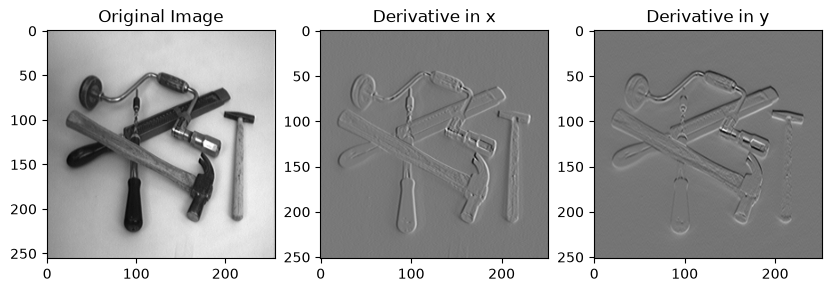

In [30]:
tools = np.load("../Images-npy/few256.npy")

dxtools = convolve2d(tools, deltax(), 'valid')
dytools = convolve2d(tools, deltay(), 'valid')

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(tools, cmap='gray')
plt.title("Original Image")
plt.subplot(1, 3, 2)
plt.imshow(dxtools, cmap='gray')
plt.title("Derivative in x")
plt.subplot(1, 3, 3)
plt.imshow(dytools, cmap='gray')
plt.title("Derivative in y")

## 2 Point–wise thresholding of gradient magnitudes

<BarContainer object of 100 artists>

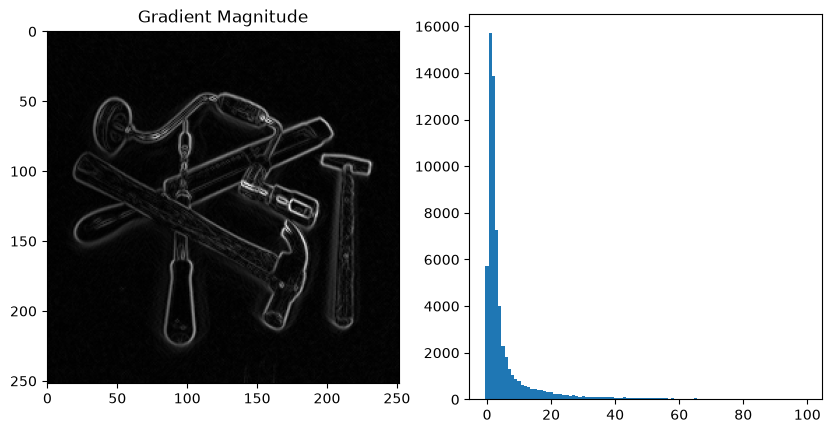

In [31]:
gradmagntools = np.sqrt(dxtools**2 + dytools**2)
histogram = np.histogram(gradmagntools, bins=100, range=(0, 100))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gradmagntools, cmap='gray')
plt.title("Gradient Magnitude")
plt.subplot(1, 2, 2)
plt.bar(histogram[1][:-1], histogram[0], width=1)

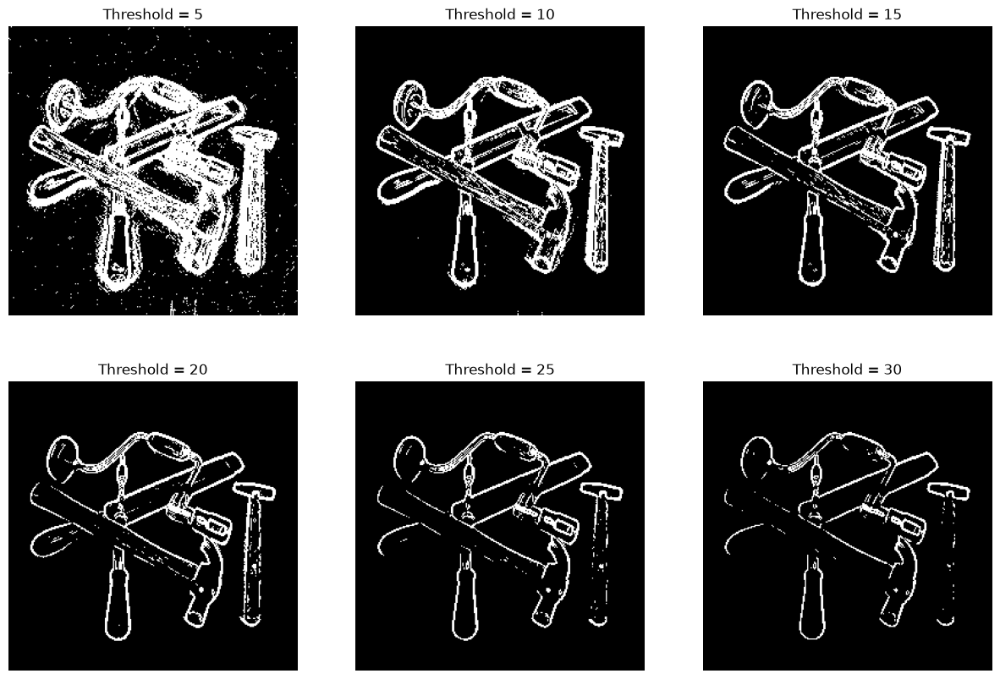

In [32]:
thresholds = [5, 10, 15, 20, 25, 30]
plt.figure(figsize=(15, 10))
for i, threshold in enumerate(thresholds):
    plt.subplot(2, 3, i + 1)
    plt.title(f"Threshold = {threshold}")
    showgrey((gradmagntools > threshold).astype(int), display=False)


(256, 256) (256, 256) (256, 256)


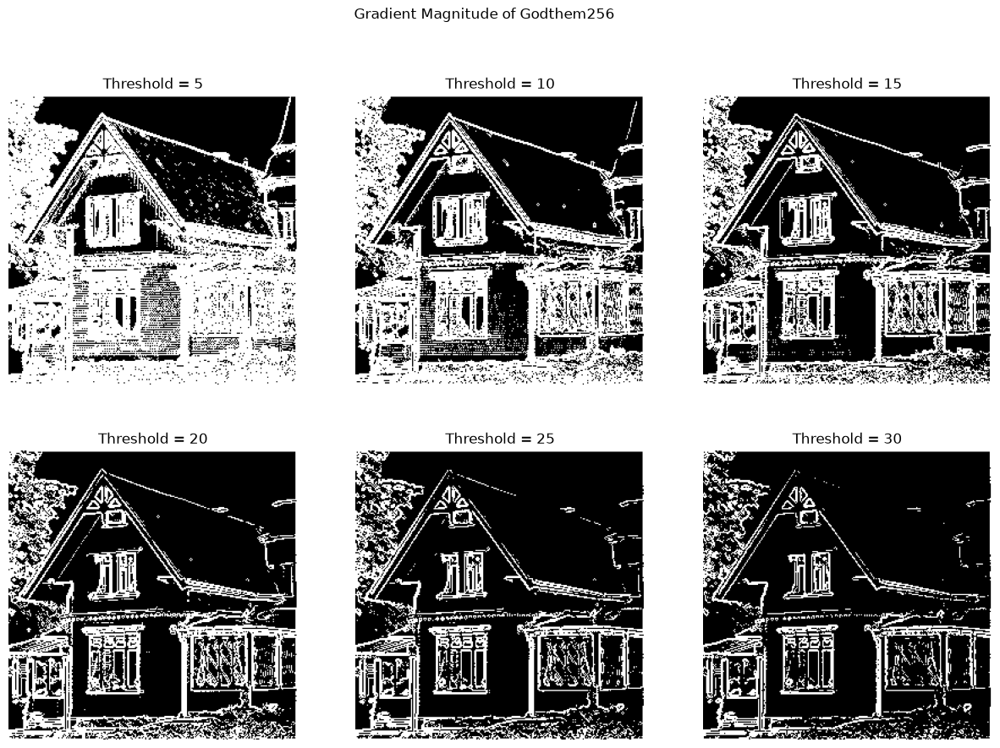

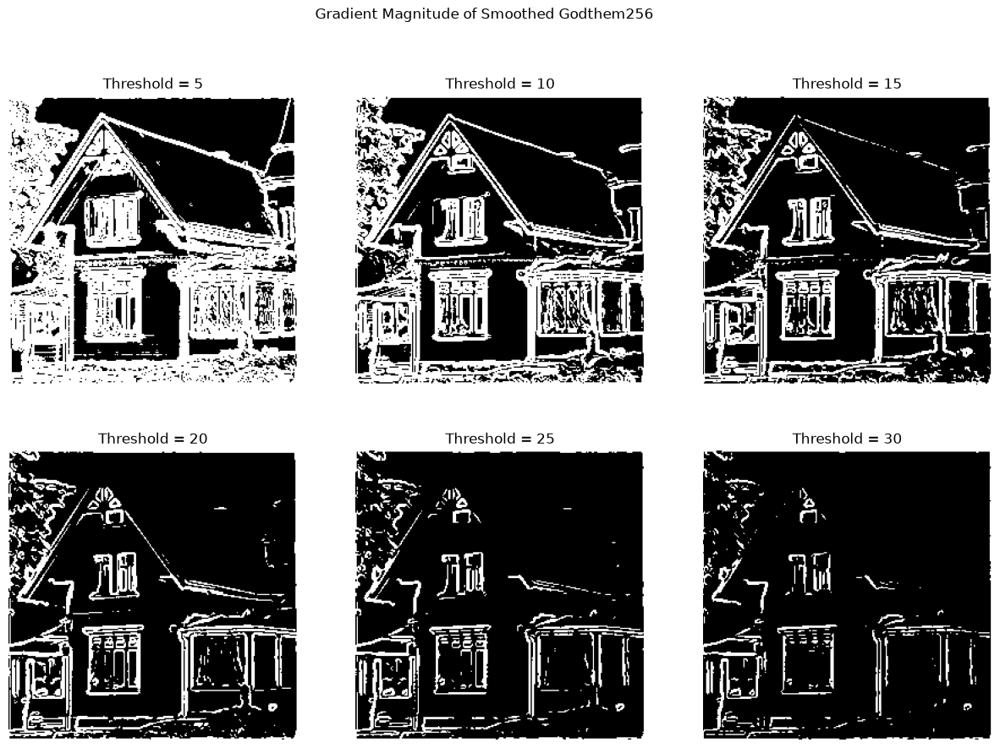

In [33]:
godthem256 = np.load("../Images-npy/godthem256.npy")

# Gaussian smoothing before same analysis
godthem256_smoothed = discgaussfft(godthem256, 1.0)

Lv_godthem256_smoothed = Lv(godthem256_smoothed, shape='same')
Lv_godthem256 = Lv(godthem256, shape='same')

plt.figure(figsize=(15, 10))
plt.suptitle("Gradient Magnitude of Godthem256")
for i, threshold in enumerate(thresholds):
    plt.subplot(2, 3, i + 1)
    plt.title(f"Threshold = {threshold}")
    showgrey((Lv_godthem256 > threshold).astype(int), display=False)
plt.show()

plt.figure(figsize=(15, 10))
plt.suptitle("Gradient Magnitude of Smoothed Godthem256")
for i, threshold in enumerate(thresholds):
    plt.subplot(2, 3, i + 1)
    plt.title(f"Threshold = {threshold}")
    showgrey((Lv_godthem256_smoothed > threshold).astype(int), display=False)
plt.show()

## 3. Differential geometry based edge detection: Theory

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


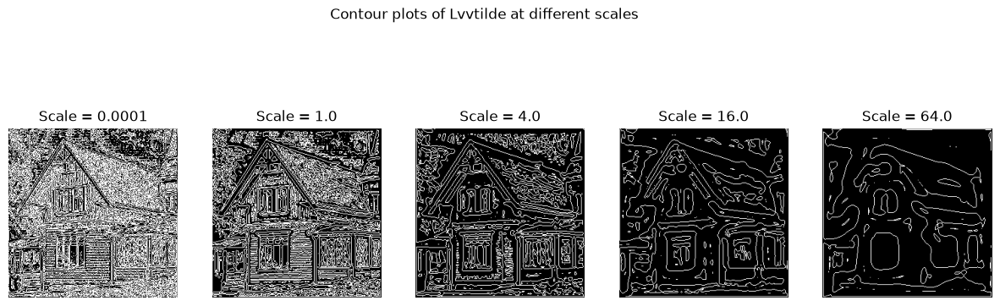

In [34]:
house = np.load("../Images-npy/godthem256.npy")
scales = [0.0001, 1.0, 4.0, 16.0, 64.0]
plt.figure(figsize=(15, 5))
plt.suptitle("Contour plots of Lvvtilde at different scales")
for scale in scales:
    plt.subplot(1, 5, scales.index(scale) + 1)
    plt.title(f"Scale = {scale}")
    showgrey(contour(Lvvtilde(discgaussfft(house, scale), 'same')), display=False)

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


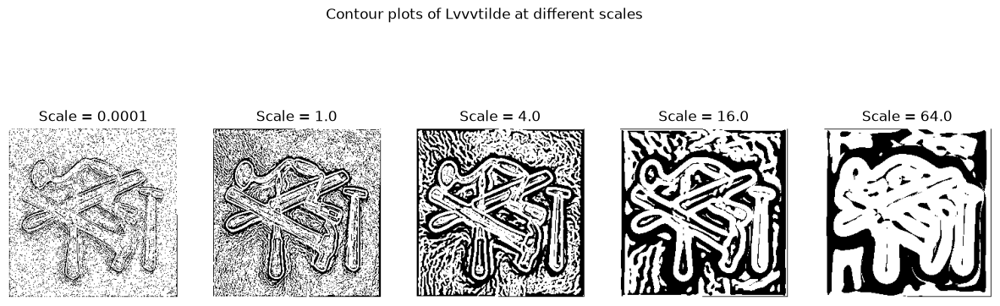

In [46]:
tools = np.load("../Images-npy/few256.npy")
scales = [0.0001, 1.0, 4.0, 16.0, 64.0]
plt.figure(figsize=(15, 5))
plt.suptitle("Contour plots of Lvvvtilde at different scales")
for scale in scales:
    plt.subplot(1, 5, scales.index(scale) + 1)
    plt.title(f"Scale = {scale}")
    showgrey((Lvvvtilde(discgaussfft(tools, scale), 'same')<0).astype(int), display=False)

## 5. Extraction of edge segments

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


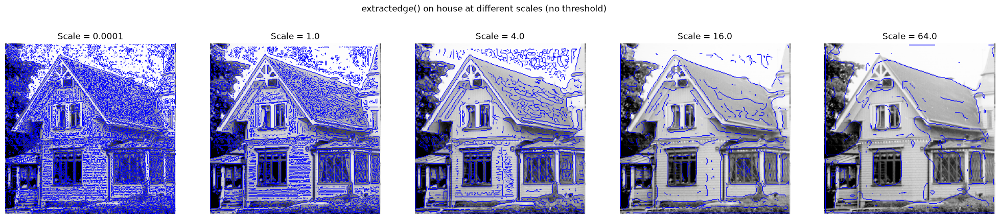

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


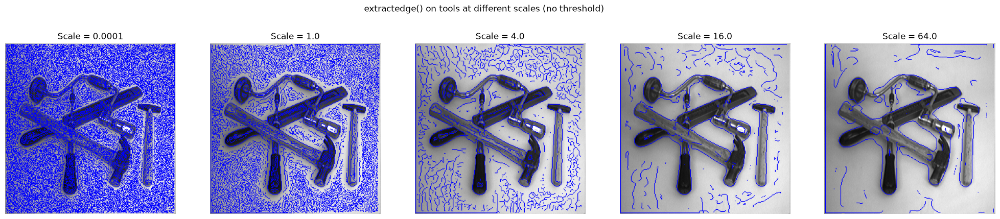

In [36]:
house = np.load("../Images-npy/godthem256.npy")
tools = np.load("../Images-npy/few256.npy")
scales = [0.0001, 1.0, 4.0, 16.0, 64.0]

# Edges at different scales, no gradient magnitude threshold
for name, img in [("house", house), ("tools", tools)]:
    plt.figure(figsize=(25, 5))
    plt.suptitle(f"extractedge() on {name} at different scales (no threshold)")
    for i, scale in enumerate(scales):
        plt.subplot(1, 5, i + 1)
        plt.title(f"Scale = {scale}")
        overlaycurves(img, extractedge(img, scale))
    plt.show()

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


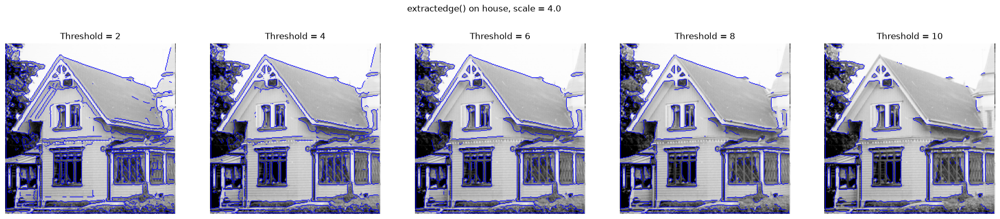

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


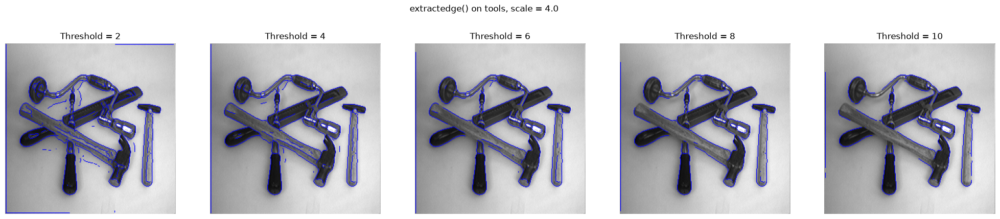

In [38]:
# Adjust the gradient magnitude threshold at the chosen scale
thresholds = [2, 4, 6, 8, 10]
best_scale = 4.0

for name, img in [("house", house), ("tools", tools)]:
    plt.figure(figsize=(25, 5))
    plt.suptitle(f"extractedge() on {name}, scale = {best_scale}")
    for i, threshold in enumerate(thresholds):
        plt.subplot(1, 5, i + 1)
        plt.title(f"Threshold = {threshold}")
        overlaycurves(img, extractedge(img, best_scale, threshold))
    plt.show()

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


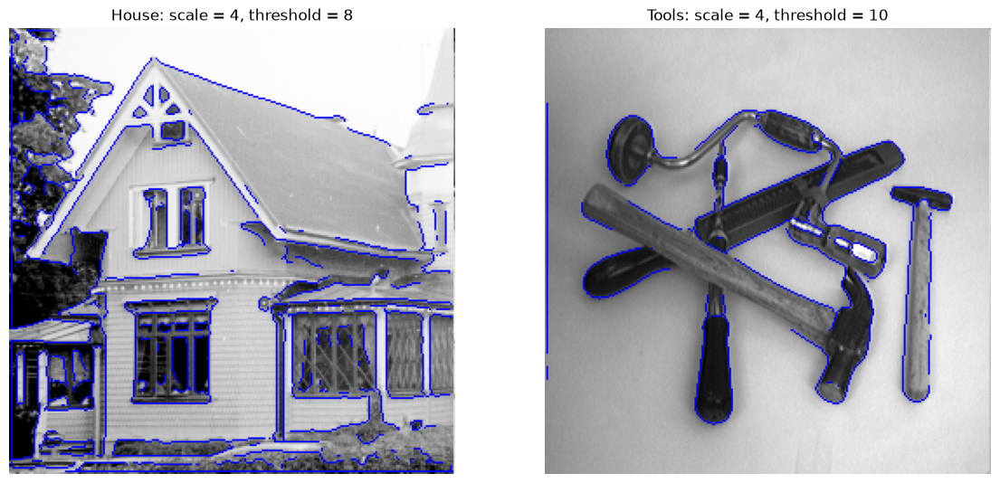

In [39]:
# Best results (Question 7)
plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.title("House: scale = 4, threshold = 8")
overlaycurves(house, extractedge(house, 4.0, 8))
plt.subplot(1, 2, 2)
plt.title("Tools: scale = 4, threshold = 10")
overlaycurves(tools, extractedge(tools, 4.0, 10))
plt.show()

## 6. Hough transform

### 6.1 Test images

In [40]:
# Sanity check: a vertical line at column 40 of a 64x64 image has
# x = 40 - 32 = 8 in centered coordinates, so we expect rho = 8, theta = 0
Y = np.arange(64)
X = np.full(64, 40)
linepar, _ = houghline((Y, X), np.ones((64, 64)), 91, 180, 0, nlines=1)
print("rho = %.2f, theta = %.1f deg" % (linepar[0][0], np.degrees(linepar[0][1])))

rho = 8.05, theta = 0.0 deg


(128, 128) (128, 128) (128, 128)
(128, 128) (128, 128) (128, 128)


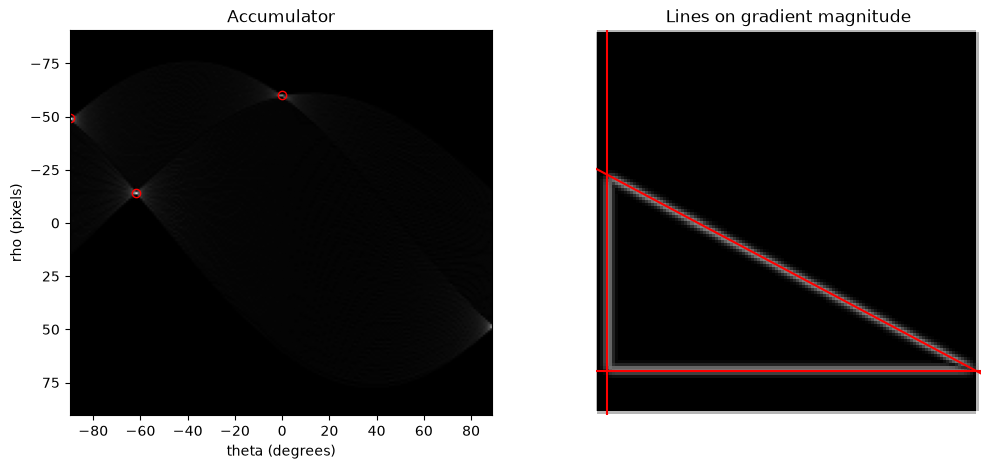

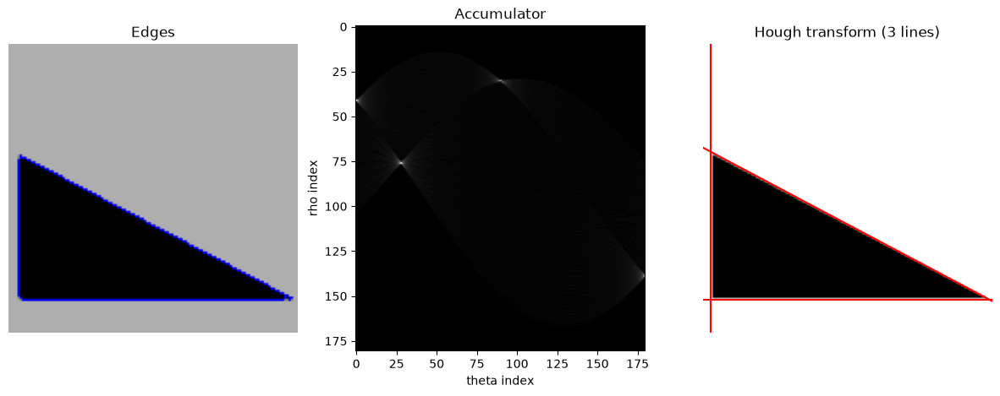

In [41]:
# Question 8: triangle, the 3 strongest peaks should match the 3 sides
triangle = np.load("../Images-npy/triangle128.npy")
linepar, acc = houghedgeline(triangle, 1.0, 10, 181, 180, nlines=3, verbose=2)

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


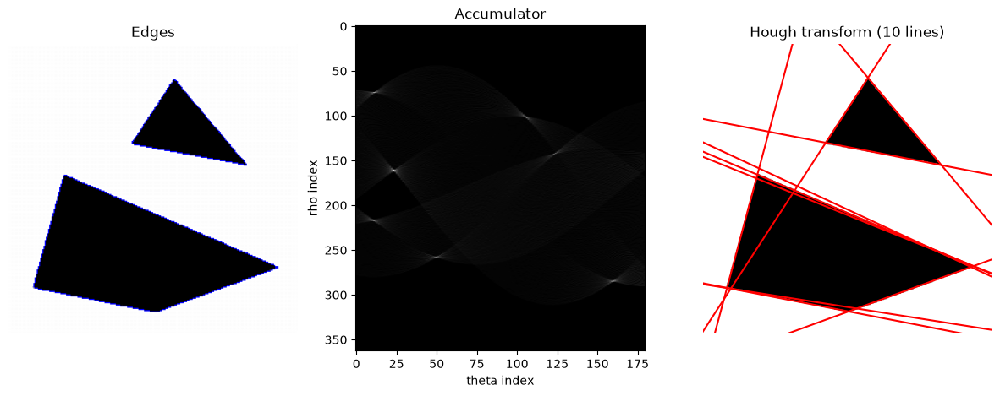

In [42]:
houghtest = np.load("../Images-npy/houghtest256.npy")
linepar, acc = houghedgeline(houghtest, 1.0, 10, 363, 180, nlines=10, verbose=1)

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


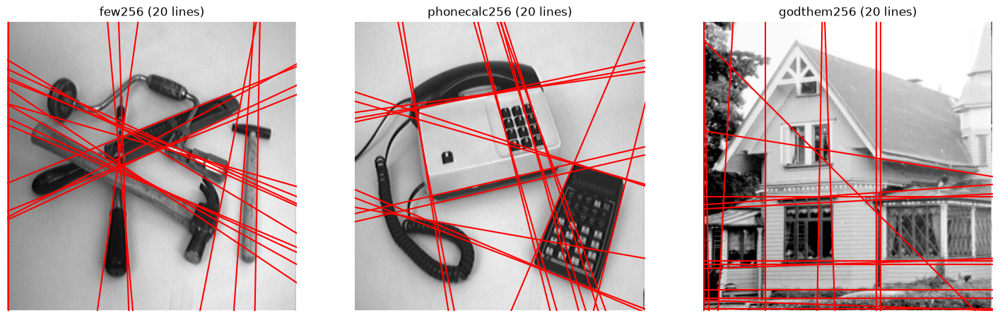

In [43]:
def show_hough_lines(img, linepar, title):
    h, w = np.shape(img)
    showgrey(img, display=False)
    for rho, theta in linepar:
        drawline(rho, theta, (w / 2, h / 2), np.hypot(w, h))
    plt.xlim(0, w)
    plt.ylim(h, 0)
    plt.title(title)

few = np.load("../Images-npy/few256.npy")
phonecalc = np.load("../Images-npy/phonecalc256.npy")
godthem = np.load("../Images-npy/godthem256.npy")
images = {"few256": few, "phonecalc256": phonecalc, "godthem256": godthem}

plt.figure(figsize=(18, 6))
for i, (name, img) in enumerate(images.items()):
    linepar, acc = houghedgeline(img, 4.0, 10, 363, 180, nlines=20)
    plt.subplot(1, 3, i + 1)
    show_hough_lines(img, linepar, f"{name} (20 lines)")
plt.show()

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


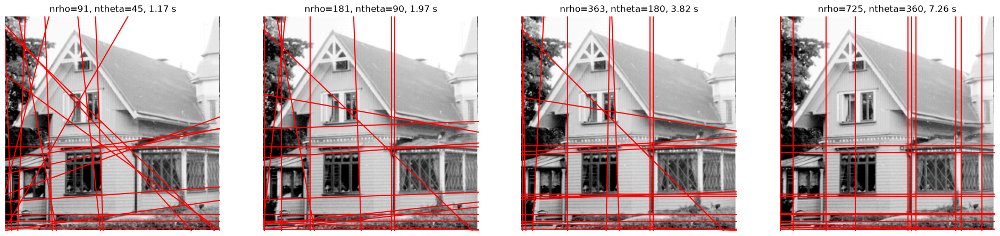

In [44]:
# Question 9: dependence on the number of accumulator cells
import time

sizes = [(91, 45), (181, 90), (363, 180), (725, 360)]
plt.figure(figsize=(24, 6))
for i, (nrho, ntheta) in enumerate(sizes):
    start = time.time()
    linepar, acc = houghedgeline(godthem, 4.0, 10, nrho, ntheta, nlines=20)
    elapsed = time.time() - start
    plt.subplot(1, 4, i + 1)
    show_hough_lines(godthem, linepar, f"nrho={nrho}, ntheta={ntheta}, {elapsed:.2f} s")
plt.show()

### 6.2 Choice of accumulator incrementation function

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


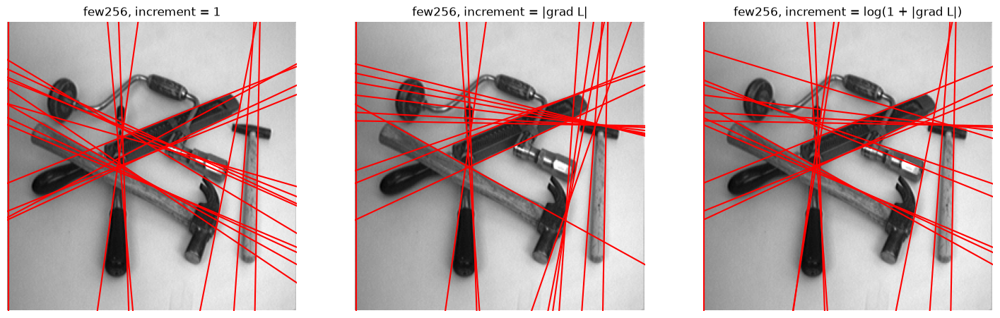

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


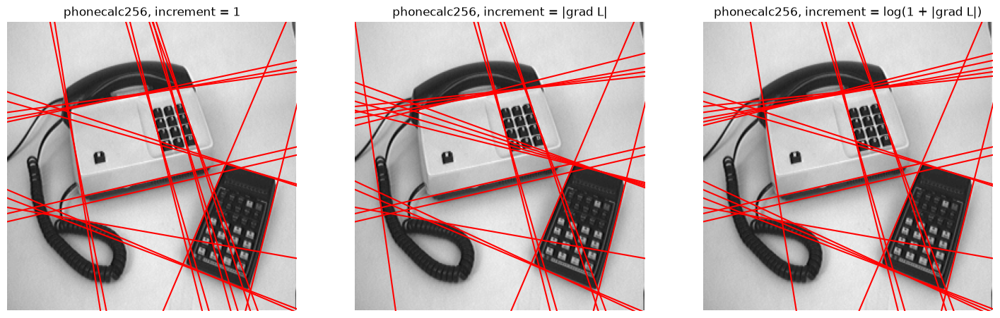

(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)
(256, 256) (256, 256) (256, 256)


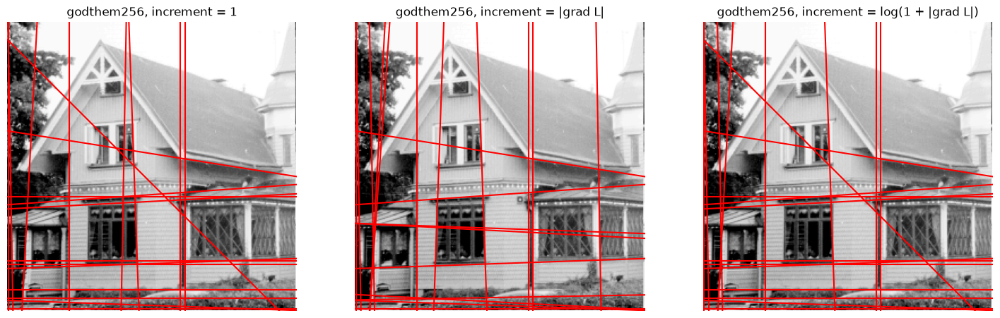

In [45]:
# Question 10: increment 1 vs. h(|grad L|) = |grad L| vs. h(|grad L|) = log(1 + |grad L|)
increments = {
    "1": None,
    "|grad L|": lambda m: m,
    "log(1 + |grad L|)": lambda m: np.log(1 + m),
}

for name, img in images.items():
    plt.figure(figsize=(18, 6))
    for i, (label, increment) in enumerate(increments.items()):
        linepar, acc = houghedgeline(img, 4.0, 10, 363, 180, nlines=20, increment=increment)
        plt.subplot(1, 3, i + 1)
        show_hough_lines(img, linepar, f"{name}, increment = {label}")
    plt.show()